# Churn Labels and Snapshots

**Goal:** decide who is scored, and whether each customer churned, for every snapshot date.
**Input:** `sales.parquet` from `01_data_cleaning.ipynb`. **Output:** `labels.parquet`.

## Setup

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Markdown, display

# One clean style for all charts
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 4)

# Folder where the charts are saved (they will be used in the README)
fig_dir = Path("../reports/figures")
fig_dir.mkdir(parents=True, exist_ok=True)


def takeaway(text):
    # Show the takeaway under a chart. The numbers are computed from the data.
    display(Markdown("**Takeaway:** " + text))

## Load the cleaned data

In [2]:
# Load the cleaned sales table saved by the cleaning notebook
sales = pd.read_parquet("../data/processed/sales.parquet")

# Revenue of each row = quantity x price
sales["line_total"] = sales["quantity"] * sales["price"]

# One row per invoice (one purchase = one invoice)
invoices = (
    sales.groupby(["customer_id", "invoice"])
    .agg(invoice_date=("invoicedate", "min"), revenue=("line_total", "sum"))
    .reset_index()
)

print("Invoices:", f"{len(invoices):,}", "| Customers:", f"{invoices['customer_id'].nunique():,}")
print("Data from", invoices["invoice_date"].min().date(), "to", invoices["invoice_date"].max().date())

Invoices: 36,480 | Customers: 5,851
Data from 2009-12-01 to 2011-12-09


## Are there long periods with no invoices (holiday closure)?

In [3]:
# Number of invoices on every calendar day
daily = invoices.set_index("invoice_date")["invoice"].resample("D").nunique()

# Find runs of consecutive days with no invoice at all
d = daily.rename("n").reset_index()
d["zero"] = d["n"] == 0
d["run"] = (d["zero"] != d["zero"].shift()).cumsum()
runs = d[d["zero"]].groupby("run").agg(start=("invoice_date", "min"), end=("invoice_date", "max"), days=("n", "size"))

# The 5 longest periods without invoices
longest = runs.sort_values("days", ascending=False).head(5)
display(longest)

if len(longest) == 0:
    takeaway("Every calendar day has at least one invoice, so there is no closure to worry about.")
else:
    periods = "; ".join(f"{r.start:%d %b %Y} to {r.end:%d %b %Y} ({r.days} days)" for r in longest.head(3).itertuples())
    takeaway(
        f"The longest periods without any invoice are: {periods}. "
        "If these fall around Christmas, the shop was closed, so a snapshot whose label window covers a closure shows "
        "extra churn that is not real behaviour."
    )

,start,end,days
run,,,
6,2009-12-24,2010-01-03,11
114,2010-12-24,2011-01-03,11
146,2011-04-22,2011-04-25,4
32,2010-04-02,2010-04-05,4
148,2011-04-29,2011-04-30,2


**Takeaway:** The longest periods without any invoice are: 24 Dec 2009 to 03 Jan 2010 (11 days); 24 Dec 2010 to 03 Jan 2011 (11 days); 22 Apr 2011 to 25 Apr 2011 (4 days). If these fall around Christmas, the shop was closed, so a snapshot whose label window covers a closure shows extra churn that is not real behaviour.

## Define the churn rule and the snapshot dates

**Design:** a *snapshot* is one cutoff date. For every customer who was active before it, the label says whether they bought in the next 90 open days.

- **Train:** one snapshot every 30 days from Jun 2010 to Mar 2011. This gives about ten times more training rows than three snapshots and covers busy and quiet seasons.
- **Valid:** one snapshot on 12 Jun 2011, used to choose and tune the model.
- **Test:** one snapshot on 10 Sep 2011, used once at the very end.
- Days when the shop was closed for a week or more (Christmas) do not count towards the 90 days.
- Every label window ends before the next period starts, so nothing from the future leaks into an earlier period.

In [4]:
# Churn rule: a customer churns if they make NO purchase in the next 90 days the shop was open
label_days = 90

# Only score customers who were still "alive": at least one purchase in the 180 days before the cutoff
active_days = 180

# Closed periods: 7 or more days in a row without any invoice (Christmas).
# Short empty periods (for example a weekend) are normal and are not counted.
closures = runs[runs["days"] >= 7]
closed_days = set()
for row in closures.itertuples():
    closed_days.update(pd.date_range(row.start, row.end))
print("Closed days found:", len(closed_days))

# Training snapshots: one every 30 days (10 snapshots), so the model sees all seasons
train_cutoffs = pd.date_range("2010-06-14", "2011-03-14", freq="30D")
valid_cutoff = pd.Timestamp("2011-06-12")
test_cutoff = pd.Timestamp("2011-09-10")

# All snapshots with their split name, in time order
snapshot_list = [(c, "train") for c in train_cutoffs] + [(valid_cutoff, "valid"), (test_cutoff, "test")]

Closed days found: 22


In [7]:
# The label window is the first 90 OPEN days after the cutoff (closed days do not count)
def label_end_for(cutoff):
    days = pd.date_range(cutoff, periods=label_days + 40)    # enough days, even with a closure inside
    open_days = [d for d in days if d not in closed_days]
    return open_days[label_days - 1] + pd.Timedelta(days=1)  # the day after the 90th open day


# Safety checks: a label window must never reach into a later period
one_day = pd.Timedelta(days=1)
assert label_end_for(train_cutoffs[-1]) <= valid_cutoff, "train labels reach into valid"
assert label_end_for(valid_cutoff) <= test_cutoff, "valid labels reach into test"
assert label_end_for(test_cutoff) <= invoices["invoice_date"].max() + one_day, "test labels go beyond the data"

# Show how long each label window is (90 days, plus the closed days inside it)
windows = pd.DataFrame({"cutoff": [c for c, s in snapshot_list], "split": [s for c, s in snapshot_list]})
windows["label_end"] = windows["cutoff"].apply(label_end_for)
windows["window_days"] = (windows["label_end"] - windows["cutoff"]).dt.days
windows

,cutoff,split,label_end,window_days
0,2010-06-14,train,2010-09-12,90
1,2010-07-14,train,2010-10-12,90
2,2010-08-13,train,2010-11-11,90
3,2010-09-12,train,2010-12-11,90
4,2010-10-12,train,2011-01-21,101
5,2010-11-11,train,2011-02-20,101
6,2010-12-11,train,2011-03-22,101
7,2011-01-10,train,2011-04-10,90
8,2011-02-09,train,2011-05-10,90
9,2011-03-11,train,2011-06-09,90


## Build the customer list and the churn label for one snapshot

In [8]:
# One function builds every snapshot, so train, valid and test are made with exactly the same logic
def make_snapshot(cutoff, split):
    label_end = label_end_for(cutoff)                        # end of the label window (90 open days)
    active_start = cutoff - pd.Timedelta(days=active_days)   # start of the "recent activity" window

    # PAST: everything before the cutoff (the only data the model may see)
    past = invoices[invoices["invoice_date"] < cutoff]

    # Customers with at least one purchase in the 180 days before the cutoff
    recent_customers = past[past["invoice_date"] >= active_start]["customer_id"].unique()

    # FUTURE: purchases inside the label window (used ONLY to make the label)
    future = invoices[(invoices["invoice_date"] >= cutoff) & (invoices["invoice_date"] < label_end)]
    bought_later = set(future["customer_id"])

    snap = pd.DataFrame({"customer_id": recent_customers})
    snap["cutoff"] = cutoff
    snap["split"] = split
    snap["churn"] = (~snap["customer_id"].isin(bought_later)).astype("int8")   # 1 = no purchase in the label window
    return snap

In [9]:
# Try the function on ONE snapshot (the test snapshot) before building all of them
example = make_snapshot(test_cutoff, "test")
print("Customers in this snapshot:", len(example))
print("Churn rate:", round(example["churn"].mean() * 100, 1), "%")
example.head()

Customers in this snapshot: 2783
Churn rate: 38.3 %


,customer_id,cutoff,split,churn
0,12347,2011-09-10,test,0
1,12348,2011-09-10,test,0
2,12352,2011-09-10,test,0
3,12353,2011-09-10,test,1
4,12354,2011-09-10,test,1


## Build all snapshots and check the churn rate

In [10]:
# Build every snapshot and stack them into one table
labels = pd.concat([make_snapshot(c, s) for c, s in snapshot_list], ignore_index=True)

# Customers and churn rate in each snapshot
summary = labels.groupby(["cutoff", "split"], as_index=False).agg(
    customers=("customer_id", "count"), churn_rate=("churn", "mean")
)
display(summary.assign(churn_rate=summary["churn_rate"].round(3)))

,cutoff,split,customers,churn_rate
0,2010-06-14,train,2621,0.507
1,2010-07-14,train,2788,0.469
2,2010-08-13,train,2825,0.406
3,2010-09-12,train,2819,0.382
4,2010-10-12,train,3014,0.440
5,2010-11-11,train,3261,0.527
6,2010-12-11,train,3472,0.626
7,2011-01-10,train,3377,0.611
8,2011-02-09,train,3361,0.594
9,2011-03-11,train,3347,0.577


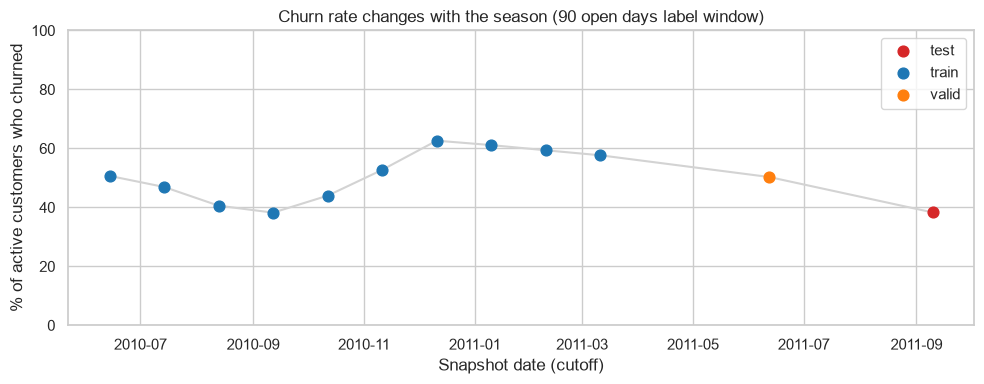

**Takeaway:** Across the 10 training snapshots the churn rate goes from 38% (12 Sep 2010) to 63% (11 Dec 2010), on average 51%. The valid snapshot has 50% and the test snapshot 38%. Because the base rate changes with the season, models are compared with lift and ranking metrics, not only raw scores. The same customer appears in several snapshots, so we always validate on the later valid snapshot, never on random rows.

In [11]:
# Chart: churn rate of every snapshot over time
colors = {"train": "tab:blue", "valid": "tab:orange", "test": "tab:red"}
fig, ax = plt.subplots()
ax.plot(summary["cutoff"], summary["churn_rate"] * 100, color="lightgrey", zorder=1)
for split, part in summary.groupby("split"):
    ax.scatter(part["cutoff"], part["churn_rate"] * 100, color=colors[split], label=split, s=60, zorder=2)
ax.set_title("Churn rate changes with the season (90 open days label window)")
ax.set_xlabel("Snapshot date (cutoff)")
ax.set_ylabel("% of active customers who churned")
ax.set_ylim(0, 100)
ax.legend()
plt.tight_layout()
plt.savefig(fig_dir / "churn_rate_by_snapshot.png", dpi=150, bbox_inches="tight")
plt.show()

train_part = summary[summary["split"] == "train"]
hi = train_part.loc[train_part["churn_rate"].idxmax()]
lo = train_part.loc[train_part["churn_rate"].idxmin()]
valid_rate = summary.loc[summary["split"] == "valid", "churn_rate"].iloc[0]
test_rate = summary.loc[summary["split"] == "test", "churn_rate"].iloc[0]
takeaway(
    f"Across the {len(train_part)} training snapshots the churn rate goes from {lo['churn_rate']:.0%} ({lo['cutoff']:%d %b %Y}) "
    f"to {hi['churn_rate']:.0%} ({hi['cutoff']:%d %b %Y}), on average {train_part['churn_rate'].mean():.0%}. "
    f"The valid snapshot has {valid_rate:.0%} and the test snapshot {test_rate:.0%}. "
    "Because the base rate changes with the season, models are compared with lift and ranking metrics, not only raw scores. "
    "The same customer appears in several snapshots, so we always validate on the later valid snapshot, never on random rows."
)

## Sanity checks

In [12]:
# Each customer must appear only once inside a snapshot
print("Duplicate customer rows inside a snapshot:", labels.duplicated(subset=["customer_id", "cutoff"]).sum())

# The label must be only 0 or 1
print("Churn values:", sorted(labels["churn"].unique().tolist()))

# Every scored customer must have bought something BEFORE the cutoff
first_purchase = invoices.groupby("customer_id")["invoice_date"].min()
assert (labels["cutoff"] > labels["customer_id"].map(first_purchase)).all(), "a customer is scored before their first purchase"

# Rows, customers and churn rate for each split
labels.groupby("split").agg(
    rows=("churn", "size"), customers=("customer_id", "nunique"), churn_rate=("churn", "mean")
).round(3)

Duplicate customer rows inside a snapshot: 0
Churn values: [0, 1]


,rows,customers,churn_rate
split,,,
test,2783,2783,0.383
train,30885,4484,0.520
valid,2629,2629,0.503


In [13]:
# Save the labels so the feature notebook can start from them
labels.to_parquet("../data/processed/labels.parquet", index=False)
print("Saved labels:", f"{len(labels):,}", "rows")

Saved labels: 36,297 rows


## Findings

In [14]:
rows = labels.groupby("split").size()
display(Markdown(f"""
- Churn rule: no purchase in the next {label_days} open days, scored only for customers with a purchase in the last {active_days} days.
- {len(train_cutoffs)} training snapshots ({rows['train']:,} rows), 1 valid snapshot ({rows['valid']:,} rows) and 1 test snapshot ({rows['test']:,} rows).
- Churn rate: train {train_part['churn_rate'].min():.0%} to {train_part['churn_rate'].max():.0%}, valid {valid_rate:.0%}, test {test_rate:.0%}.
- The churn rate depends on the season, so models are compared with lift and ranking metrics.
- Next: build features for every snapshot using only data before its cutoff date.
"""))


- Churn rule: no purchase in the next 90 open days, scored only for customers with a purchase in the last 180 days.
- 10 training snapshots (30,885 rows), 1 valid snapshot (2,629 rows) and 1 test snapshot (2,783 rows).
- Churn rate: train 38% to 63%, valid 50%, test 38%.
- The churn rate depends on the season, so models are compared with lift and ranking metrics.
- Next: build features for every snapshot using only data before its cutoff date.
